# DATA 501 — SQL Module Project
## Own the Database: Ride Knox Goes Upstream for Good

**Name:** Raymond Kojo Kyei
**NetID:** rkyei
**Working branch:** `feature/sql-module-project`

This notebook rebuilds `ride_knox_v2.db` from the five raw Ride Knox files and then produces the reconciliation, reporting, chart, and index evidence required by the project.

### Reproducibility rule
The raw files are never modified. The database is a disposable build product: **Kernel → Restart & Run All** deletes the previous build and recreates it from the source files.

### Pipeline
**raw files → staging → SQL normalization → reconciliation → constrained migration → shared reporting view → board reports → indexes**


# Part 0 — Setup and helpers

Every connection enables foreign-key enforcement. Parameterized reports use `?` placeholders and `params=`; no report values are built with SQL f-strings.


In [1]:
from pathlib import Path
import sqlite3
import time

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('.')
SQL_DIR = ROOT / 'sql'
CHART_DIR = ROOT / 'charts'
CHART_DIR.mkdir(exist_ok=True)
DB = ROOT / 'ride_knox_v2.db'

RAW_FILES = {
    'trips_2025': ROOT / 'trips_2025.csv',
    'stations_2025': ROOT / 'stations.xlsx',
    'trips_2026_h1': ROOT / 'trips_2026_h1.csv',
    'stations_2026': ROOT / 'stations_2026.xlsx',
    'trips_2026_07': ROOT / 'trips_2026_07.csv',
}
missing = [str(p) for p in RAW_FILES.values() if not p.exists()]
assert not missing, f'Missing required raw files: {missing}'

if DB.exists():
    DB.unlink()

con = sqlite3.connect(DB)
con.execute('PRAGMA foreign_keys = ON;')
foreign_keys = con.execute('PRAGMA foreign_keys;').fetchone()[0]
print('foreign_keys:', foreign_keys)
assert foreign_keys == 1


foreign_keys: 1


In [2]:
def sql_block(filename, block_name):
    text = (SQL_DIR / filename).read_text(encoding='utf-8')
    start = f'-- >>> {block_name}'
    end = f'-- <<< {block_name}'
    assert start in text and end in text, f'Missing SQL block: {block_name}'
    return text.split(start, 1)[1].split(end, 1)[0].strip()


def execute_block(filename, block_name, params=()):
    return con.execute(sql_block(filename, block_name), params)


def read_block(filename, block_name, params=()):
    return pd.read_sql(sql_block(filename, block_name), con, params=params)


def try_block(filename, block_name):
    try:
        con.execute('BEGIN;')
        con.execute(sql_block(filename, block_name))
        con.execute('ROLLBACK;')
        return 'ACCEPTED — unexpected for a deliberate rejection test'
    except Exception as exc:
        if con.in_transaction:
            con.execute('ROLLBACK;')
        return f'REFUSED -> {exc}'


def db_size_mb():
    return round(DB.stat().st_size / (1024 * 1024), 1)


def timed_read(sql, params=(), repeats=5):
    result = None
    start = time.perf_counter()
    for _ in range(repeats):
        result = pd.read_sql(sql, con, params=params)
    return result, round((time.perf_counter() - start) * 1000 / repeats, 2)

print('helpers ready')


helpers ready


# Part A — Schema design and data dictionary

The production design separates station facts, capacity history, rider products, bike types, accepted trips, and excluded source rows. Product and bike categories use lookup tables so a future launch can be registered without rebuilding the trip structure. Historical dock counts use effective dates so each reporting period can retrieve its own denominator.

The full column-by-column documentation and design trade-offs are in `DATA-DICTIONARY.md`.


In [3]:
for block in [
    'CREATE_RIDER_PRODUCTS', 'CREATE_BIKE_TYPES', 'CREATE_STATIONS',
    'CREATE_CAPACITY_HISTORY', 'CREATE_TRIPS', 'CREATE_EXCLUSIONS'
]:
    execute_block('schema.sql', block)
print('production schema created')


production schema created


# Part B — Stage the five raw files

All five files land in staging first. The only Python-side addition to trip files is `source_row`, an audit number that allows every raw row to be named during reconciliation. Cleaning/normalization happens later in SQL.


In [4]:
trips_2025 = pd.read_csv(RAW_FILES['trips_2025'])
stations_2025 = pd.read_excel(RAW_FILES['stations_2025'])
trips_2026_h1 = pd.read_csv(RAW_FILES['trips_2026_h1'])
stations_2026 = pd.read_excel(RAW_FILES['stations_2026'])
trips_2026_07 = pd.read_csv(RAW_FILES['trips_2026_07'])

def with_source_row(df):
    out = df.copy()
    out.insert(0, 'source_row', range(1, len(out) + 1))
    return out

with_source_row(trips_2025).to_sql('stg_trips_2025_raw', con, if_exists='replace', index=False)
stations_2025.to_sql('stg_stations_2025', con, if_exists='replace', index=False)
with_source_row(trips_2026_h1).to_sql('stg_trips_2026_h1_raw', con, if_exists='replace', index=False)
stations_2026.to_sql('stg_stations_2026', con, if_exists='replace', index=False)
with_source_row(trips_2026_07).to_sql('stg_trips_2026_07_raw', con, if_exists='replace', index=False)

print('stations.xlsx rows:', len(stations_2025))
print('stations_2026.xlsx rows:', len(stations_2026))
print('trips_2025.csv rows:', len(trips_2025))
print('trips_2026_h1.csv rows:', len(trips_2026_h1))
print('trips_2026_07.csv rows:', len(trips_2026_07))
assert len(trips_2026_07) == 33085

# pandas to_sql is much faster with the normal transaction mode.
# Switch to explicit autocommit only after staging is complete.
con.commit()
con.isolation_level = None


stations.xlsx rows: 24
stations_2026.xlsx rows: 25
trips_2025.csv rows: 250600
trips_2026_h1.csv rows: 137341
trips_2026_07.csv rows: 33085


In [5]:
# Reconcile both station source files, then load dimensions/capacity.
execute_block('reconciliation.sql', 'RECON_STATIONS_2025')
execute_block('reconciliation.sql', 'RECON_STATIONS_2026')

for block in [
    'SEED_PRODUCTS', 'SEED_BIKE_TYPES', 'LOAD_STATIONS',
    'CAPACITY_BASELINE_2025', 'CAPACITY_S06', 'CAPACITY_S08', 'CAPACITY_S25'
]:
    execute_block('load.sql', block)

station_closure = pd.DataFrame([
    {'file': 'stations.xlsx', 'raw_rows': len(stations_2025),
     'accounted_rows': int(pd.read_sql('SELECT COUNT(*) AS n FROM recon_stations_2025;', con).loc[0, 'n'])},
    {'file': 'stations_2026.xlsx', 'raw_rows': len(stations_2026),
     'accounted_rows': int(pd.read_sql('SELECT COUNT(*) AS n FROM recon_stations_2026;', con).loc[0, 'n'])},
])
display(station_closure)
assert (station_closure['raw_rows'] == station_closure['accounted_rows']).all()

display(pd.read_sql('SELECT * FROM station_capacity_history ORDER BY station_id, effective_date;', con))


,file,raw_rows,accounted_rows
0,stations.xlsx,24,24
1,stations_2026.xlsx,25,25


,station_id,effective_date,docks,event_type,note
0,S01,2025-01-01,20,baseline,2025 published station directory
1,S02,2025-01-01,16,baseline,2025 published station directory
2,S03,2025-01-01,12,baseline,2025 published station directory
3,S04,2025-01-01,16,baseline,2025 published station directory
4,S05,2025-01-01,20,baseline,2025 published station directory
5,S06,2025-01-01,24,baseline,2025 published station directory
6,S06,2026-02-15,32,expansion,Hodges Library expansion
7,S07,2025-01-01,12,baseline,2025 published station directory
8,S08,2025-01-01,24,baseline,2025 published station directory
9,S08,2026-02-15,32,expansion,Student Union expansion


## Part A — Demonstrated constraint rejections

The next three statements are deliberately invalid. Each tests a different constraint, and each is executed inside a transaction that is rolled back so the demonstration cannot alter the production data.


In [6]:
for label, block in [
    ('CHECK constraint — docks must be positive', 'TEST_BAD_DOCKS'),
    ('FOREIGN KEY — start station must exist', 'TEST_BAD_FOREIGN_KEY'),
    ('NOT NULL — start_time is required', 'TEST_BAD_NOT_NULL'),
]:
    print(label)
    print(try_block('schema.sql', block))
    print()


CHECK constraint — docks must be positive
REFUSED -> CHECK constraint failed: docks > 0

FOREIGN KEY — start station must exist
REFUSED -> FOREIGN KEY constraint failed

NOT NULL — start_time is required
REFUSED -> NOT NULL constraint failed: trips.start_time



## Part B1 — 2025 anchors, normalization, reconciliation, migration

The raw export contains 250,600 rows. After the duplicate copies are collapsed, the familiar class anchors should reappear: 250,000 unique trip IDs, 263 trips from the test station, and 3,767 trips with no end station.


In [7]:
anchors_2025 = read_block('reconciliation.sql', 'ANCHORS_2025')
display(anchors_2025)
assert int(anchors_2025.loc[0, 'raw_rows']) == 250600
assert int(anchors_2025.loc[0, 'duplicate_rows']) == 600
assert int(anchors_2025.loc[0, 'test_station_rows']) == 263
assert int(anchors_2025.loc[0, 'missing_end_station_rows']) == 3767
print('2025 anchors reproduced')


,raw_rows,duplicate_rows,test_station_rows,missing_end_station_rows
0,250600,600,263,3767


2025 anchors reproduced


In [8]:
execute_block('load.sql', 'NORMALIZE_2025')
execute_block('reconciliation.sql', 'RECON_2025')
summary_2025 = read_block('reconciliation.sql', 'SUMMARY_2025')
display(summary_2025)

raw_2025 = len(trips_2025)
accounted_2025 = int(summary_2025['rows'].sum())
predicted_2025 = int(summary_2025.loc[summary_2025['outcome'] == 'loaded', 'rows'].sum())
print('raw:', raw_2025, 'accounted:', accounted_2025, 'predicted load:', predicted_2025)
assert raw_2025 == accounted_2025


,outcome,rows
0,loaded,248990
1,impossible_timestamp,747
2,duplicate_in_file,600
3,orphan_start_station,263


raw: 250600 accounted: 250600 predicted load: 248990


In [9]:
before = int(pd.read_sql('SELECT COUNT(*) AS n FROM trips;', con).loc[0, 'n'])
execute_block('load.sql', 'MIGRATE_2025')
execute_block('load.sql', 'EXCLUSIONS_2025')
after = int(pd.read_sql('SELECT COUNT(*) AS n FROM trips;', con).loc[0, 'n'])
actual_2025 = after - before
print('2025 predicted:', predicted_2025)
print('2025 actual inserted:', actual_2025)
assert predicted_2025 == actual_2025


2025 predicted: 248990
2025 actual inserted: 248990


## Part B2 — 2026 H1 normalization, reconciliation, migration

The first-half file is treated independently rather than assumed clean. Day Pass spelling variants are normalized in SQL, duplicate IDs are named, and impossible timestamps are kept out of the constrained trip store.


In [10]:
execute_block('load.sql', 'NORMALIZE_H1')
execute_block('reconciliation.sql', 'RECON_H1')
summary_h1 = read_block('reconciliation.sql', 'SUMMARY_H1')
display(summary_h1)

raw_h1 = len(trips_2026_h1)
accounted_h1 = int(summary_h1['rows'].sum())
predicted_h1 = int(summary_h1.loc[summary_h1['outcome'] == 'loaded', 'rows'].sum())
print('raw:', raw_h1, 'accounted:', accounted_h1, 'predicted load:', predicted_h1)
assert raw_h1 == accounted_h1


,outcome,rows
0,loaded,136811
1,duplicate_in_file,350
2,impossible_timestamp,180


raw: 137341 accounted: 137341 predicted load: 136811


In [11]:
before = int(pd.read_sql('SELECT COUNT(*) AS n FROM trips;', con).loc[0, 'n'])
execute_block('load.sql', 'MIGRATE_H1')
execute_block('load.sql', 'EXCLUSIONS_H1')
after = int(pd.read_sql('SELECT COUNT(*) AS n FROM trips;', con).loc[0, 'n'])
actual_h1 = after - before
print('H1 predicted:', predicted_h1)
print('H1 actual inserted:', actual_h1)
assert predicted_h1 == actual_h1


H1 predicted: 136811
H1 actual inserted: 136811


# Part C — July drill: inspect before moving any July row

The vendor file is treated as an unaudited stranger. The inspection below is SQL against raw staging and checks the file window, duplicate IDs, raw rider spellings, raw bike categories, missing fields, impossible time order, station-name whitespace, and the missing-start population associated with the mid-July outage.


In [12]:
for block in [
    'JULY_ROWCOUNT', 'JULY_DATE_RANGE', 'JULY_DUPLICATES',
    'JULY_RIDER_VALUES', 'JULY_BIKE_VALUES', 'JULY_CARGO_STATIONS',
    'JULY_BAD_ROWS', 'JULY_OUTAGE_CHECK'
]:
    print('---', block, '---')
    display(read_block('reconciliation.sql', block))


--- JULY_ROWCOUNT ---


,raw_rows
0,33085


--- JULY_DATE_RANGE ---


,earliest_start,latest_start,pre_july_rows,july_rows,missing_start_rows
0,2026-06-28 09:39:00,2026-07-31 23:57:00,215,32830,40


--- JULY_DUPLICATES ---


...

,start_station_id,cargo_rows
0,S04,81
1,S03,80
2,S01,68
3,S05,67
4,S02,54


--- JULY_BAD_ROWS ---


,missing_start_time,missing_end_station,impossible_timestamp,station_name_whitespace_rows
0,40,850,60,429


--- JULY_OUTAGE_CHECK ---


,earliest_end_for_missing_start,latest_end_for_missing_start,rows
0,2026-07-14 09:00:00,2026-07-14 20:43:00,40


## July inspection log and decisions

The raw July delivery contains **33,085 rows**, but it starts on **June 28**, so the export name is not used as the reporting period. The file also contains **120 repeated trip IDs**, multiple spellings of Day Pass, and a new **cargo** bike type. Cargo records cluster at downtown stations, which is consistent with the documented July pilot; I therefore register `cargo` as a legitimate type rather than reject that population.

The outage population includes rows with no start time. Those rows are quarantined because a trip without a start timestamp cannot be assigned to a reporting period. Rows whose end time is not later than their start time are also rejected as impossible. Missing end-station IDs are different: they are incomplete but can still represent a real ride, so they remain in historical storage and are excluded only from the shared reporting view.

For the overlapping June window, trip IDs already present from H1 are labeled `duplicate_existing`. A pre-July trip ID that is not already present is treated as late-arriving backlog and loaded with its original June timestamp. This preserves the vendor's backlog behavior without double counting the overlap.


In [13]:
# Only after the raw inspection do we normalize July and register cargo.
execute_block('load.sql', 'NORMALIZE_JULY')
execute_block('load.sql', 'REGISTER_CARGO')
display(pd.read_sql('SELECT * FROM bike_types ORDER BY bike_type;', con))


,bike_type,description
0,cargo,Cargo-bike type observed in the July 2026 down...
1,classic,Classic bicycle
2,electric,Electric-assist bicycle


In [14]:
execute_block('reconciliation.sql', 'RECON_JULY')
summary_july = read_block('reconciliation.sql', 'SUMMARY_JULY')
display(summary_july)

raw_july = len(trips_2026_07)
accounted_july = int(summary_july['rows'].sum())
predicted_july = int(summary_july.loc[
    summary_july['outcome'].isin(['loaded_july', 'loaded_backlog']), 'rows'
].sum())
print('raw:', raw_july, 'accounted:', accounted_july, 'predicted load:', predicted_july)
assert raw_july == 33085
assert raw_july == accounted_july


,outcome,rows
0,loaded_july,32650
1,duplicate_existing,180
2,duplicate_in_file,120
3,impossible_timestamp,60
4,missing_start_time,40
5,loaded_backlog,35


raw: 33085 accounted: 33085 predicted load: 32685


In [15]:
before = int(pd.read_sql('SELECT COUNT(*) AS n FROM trips;', con).loc[0, 'n'])
execute_block('load.sql', 'MIGRATE_JULY')
execute_block('load.sql', 'EXCLUSIONS_JULY')
after = int(pd.read_sql('SELECT COUNT(*) AS n FROM trips;', con).loc[0, 'n'])
actual_july = after - before
print('July predicted:', predicted_july)
print('July actual inserted:', actual_july)
assert predicted_july == actual_july


July predicted: 32685
July actual inserted: 32685


## Five-file closure audit

Every raw file is represented in a reconciliation result. For the three trip files, predicted accepted rows are also checked against the actual number inserted into the constrained trip store.


In [16]:
closure = pd.DataFrame([
    {'file': 'stations.xlsx', 'raw_rows': len(stations_2025),
     'accounted_rows': int(pd.read_sql('SELECT COUNT(*) AS n FROM recon_stations_2025;', con).loc[0, 'n']),
     'predicted_loaded': None, 'actual_loaded': None},
    {'file': 'stations_2026.xlsx', 'raw_rows': len(stations_2026),
     'accounted_rows': int(pd.read_sql('SELECT COUNT(*) AS n FROM recon_stations_2026;', con).loc[0, 'n']),
     'predicted_loaded': None, 'actual_loaded': None},
    {'file': 'trips_2025.csv', 'raw_rows': raw_2025, 'accounted_rows': accounted_2025,
     'predicted_loaded': predicted_2025, 'actual_loaded': actual_2025},
    {'file': 'trips_2026_h1.csv', 'raw_rows': raw_h1, 'accounted_rows': accounted_h1,
     'predicted_loaded': predicted_h1, 'actual_loaded': actual_h1},
    {'file': 'trips_2026_07.csv', 'raw_rows': raw_july, 'accounted_rows': accounted_july,
     'predicted_loaded': predicted_july, 'actual_loaded': actual_july},
])
display(closure)
assert (closure['raw_rows'] == closure['accounted_rows']).all()
trip_closure = closure[closure['predicted_loaded'].notna()]
assert (trip_closure['predicted_loaded'] == trip_closure['actual_loaded']).all()
print('ALL FILES CLOSE')


,file,raw_rows,accounted_rows,predicted_loaded,actual_loaded
0,stations.xlsx,24,24,NaN,NaN
1,stations_2026.xlsx,25,25,NaN,NaN
2,trips_2025.csv,250600,250600,248990.0,248990.0
3,trips_2026_h1.csv,137341,137341,136811.0,136811.0
4,trips_2026_07.csv,33085,33085,32685.0,32685.0


ALL FILES CLOSE


# Part D — Reporting layer

## Shared definition of a reportable trip
A trip belongs in routine reports when it has a recorded end time and end station and its positive duration is between **1 minute and 6 hours**. The same range was used in the course's duration-cleaning work. Positive records outside the range remain in the accepted history with `duration_flag = 1`, but the view keeps them out of board reporting so every downstream report uses one consistent rule.


In [17]:
execute_block('views.sql', 'REPORTING_TRIPS')
display(pd.read_sql('SELECT COUNT(*) AS reportable_trips FROM reporting_trips;', con))


,reportable_trips
0,407672


## Anniversary verdict — July 2026 versus July 2025

The project requires both definitions of non-member recovery to be visible rather than silently choosing one: **casual only** and **casual + Day Pass**.


In [18]:
july_by_product = read_block('reports.sql', 'JULY_BY_PRODUCT')
anniversary = read_block('reports.sql', 'ANNIVERSARY_DEFINITIONS')
display(july_by_product)
display(anniversary)


,july_period,rider_type,trips
0,2025-07,casual,8974
1,2025-07,member,17578
2,2026-07,casual,7504
3,2026-07,day_pass,4737
4,2026-07,member,19492


,jul_2025_casual,jul_2026_casual,jul_2026_day_pass,jul_2026_casual_plus_day_pass,casual_only_pct_change,combined_pct_change
0,8974,7504,4737,12241,-16.4,36.4


## Base-effect check

A July-to-July comparison alone can be misleading because July 2025 is the collapsed month after the price increase. The January–July series below is therefore part of the verdict, not an optional chart.


In [19]:
monthly = read_block('reports.sql', 'MONTHLY_BASE_EFFECT')
display(monthly)


,month_num,casual_2025,casual_2026,casual_plus_daypass_2026
0,1,4637,3156,3156
1,2,5575,4051,4051
2,3,8444,6516,7598
3,4,11051,8630,10808
4,5,12997,10417,13746
5,6,13595,11014,15002
6,7,8974,7504,12241


## Capacity verdict

Per-dock pressure is reported for **S06, S08, S25, S23, and S24**. Each denominator is retrieved from capacity history for the correct year. No dock count is typed into the report.


In [20]:
capacity = read_block('reports.sql', 'CAPACITY_VERDICT')
display(capacity)


,station_id,station_name,trips_2025,docks_2025,trips_per_dock_2025,trips_2026,docks_2026,trips_per_dock_2026,pressure_pct_change
0,S06,Hodges Library,2746,24.0,114.4,2528,32,79.0,-31.0
1,S08,Student Union - UT,2546,24.0,106.1,2408,32,75.3,-29.1
2,S23,Bearden - Kingston Pike,207,12.0,17.3,452,12,37.7,118.4
3,S24,Sequoyah Hills Park,215,10.0,21.5,268,10,26.8,24.7
4,S25,Cumberland Ave & 22nd St,0,NaN,NaN,2124,16,132.8,NaN


## Parameterized report the team can rerun every month

The same SQL statement is demonstrated with S06 and S25. Values are passed through `?` placeholders and `params=`.


In [21]:
station_month_sql = sql_block('reports.sql', 'PARAM_STATION_MONTH')

s06_july = pd.read_sql(station_month_sql, con, params=('S06', '2026-07-01', '2026-08-01'))
s25_july = pd.read_sql(station_month_sql, con, params=('S25', '2026-07-01', '2026-08-01'))
print('S06 — July 2026')
display(s06_july)
print('S25 — July 2026')
display(s25_july)


S06 — July 2026


,rider_type,trips
0,member,1630
1,casual,599
2,day_pass,299


S25 — July 2026


,rider_type,trips
0,member,1165
1,day_pass,516
2,casual,443


## Chart 1 — non-member recovery, January–July

The aggregation is performed in SQL; Python only draws and saves the chart.


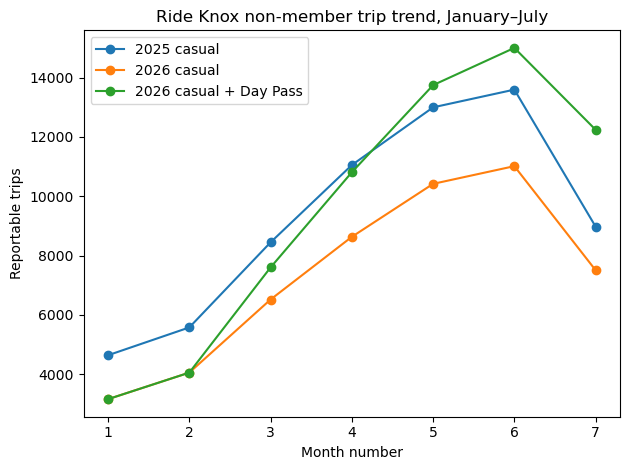

In [22]:
ax = monthly.plot(
    x='month_num',
    y=['casual_2025', 'casual_2026', 'casual_plus_daypass_2026'],
    marker='o'
)
ax.set_title('Ride Knox non-member trip trend, January–July')
ax.set_xlabel('Month number')
ax.set_ylabel('Reportable trips')
ax.legend(['2025 casual', '2026 casual', '2026 casual + Day Pass'])
plt.tight_layout()
plt.savefig(CHART_DIR / 'anniversary_recovery.png', dpi=150)
plt.show()


## Chart 2 — July trip starts per dock


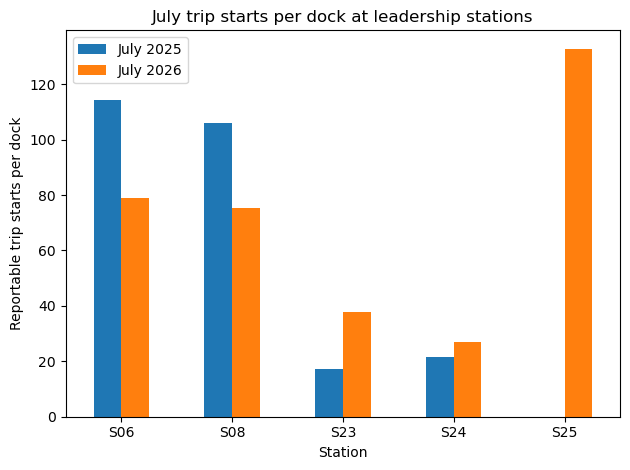

In [23]:
pressure_plot = capacity.set_index('station_id')[['trips_per_dock_2025', 'trips_per_dock_2026']]
ax = pressure_plot.plot(kind='bar')
ax.set_title('July trip starts per dock at leadership stations')
ax.set_xlabel('Station')
ax.set_ylabel('Reportable trip starts per dock')
ax.legend(['July 2025', 'July 2026'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / 'capacity_pressure.png', dpi=150)
plt.show()


# Part E — Make it fast, prove it

Two reporting queries are explained and timed before indexing. Then two justified composite indexes are created and the same evidence is collected again. The database size is recorded on both sides.


In [24]:
station_sql = sql_block('reports.sql', 'PARAM_STATION_MONTH')
product_sql = sql_block('reports.sql', 'PRODUCT_PERIOD_REPORT')
station_params = ('S06', '2026-07-01', '2026-08-01')
product_params = ('casual', '2026-07-01', '2026-08-01')

station_plan_before = pd.read_sql('EXPLAIN QUERY PLAN ' + station_sql, con, params=station_params)
product_plan_before = pd.read_sql('EXPLAIN QUERY PLAN ' + product_sql, con, params=product_params)
_, station_ms_before = timed_read(station_sql, station_params)
_, product_ms_before = timed_read(product_sql, product_params)
size_before = db_size_mb()

print('Station query plan BEFORE')
display(station_plan_before)
print('Product query plan BEFORE')
display(product_plan_before)
print('station ms before:', station_ms_before)
print('product ms before:', product_ms_before)
print('database MB before:', size_before)


Station query plan BEFORE


,id,parent,notused,detail
0,7,0,0,SCAN t
1,29,0,0,USE TEMP B-TREE FOR GROUP BY
2,64,0,0,USE TEMP B-TREE FOR ORDER BY


Product query plan BEFORE


,id,parent,notused,detail
0,3,0,0,SCAN t


station ms before: 358.23
product ms before: 220.09
database MB before: 141.1


In [25]:
execute_block('indexes.sql', 'INDEX_STATION_START')
execute_block('indexes.sql', 'INDEX_PRODUCT_START')

station_plan_after = pd.read_sql('EXPLAIN QUERY PLAN ' + station_sql, con, params=station_params)
product_plan_after = pd.read_sql('EXPLAIN QUERY PLAN ' + product_sql, con, params=product_params)
_, station_ms_after = timed_read(station_sql, station_params)
_, product_ms_after = timed_read(product_sql, product_params)
size_after = db_size_mb()

print('Station query plan AFTER')
display(station_plan_after)
print('Product query plan AFTER')
display(product_plan_after)
print('station ms after:', station_ms_after)
print('product ms after:', product_ms_after)
print('database MB after:', size_after)
print('database size increase MB:', round(size_after - size_before, 1))


Station query plan AFTER


,id,parent,notused,detail
0,8,0,0,SEARCH t USING INDEX idx_trips_station_start (...
1,34,0,0,USE TEMP B-TREE FOR GROUP BY
2,69,0,0,USE TEMP B-TREE FOR ORDER BY


Product query plan AFTER


,id,parent,notused,detail
0,4,0,0,SEARCH t USING INDEX idx_trips_product_start (...


station ms after: 8.07
product ms after: 12.72
database MB after: 168.1
database size increase MB: 27.0


## Index interpretation

The `(start_station_id, start_time)` order matches a station-month report because the station is tested for equality and the timestamp is then used as a range. The `(rider_type, start_time)` index follows the same equality-then-range pattern for product-period reporting.

The loading choices make these indexes usable: rider products are normalized before they reach `trips`, and timestamps stay in sortable ISO text, so the report filters do not need to wrap the indexed columns in `LOWER()` or `strftime()`.

I deliberately did **not** index `duration_flag`. It has only two values, so it has low selectivity; another index would add storage and write cost without a strong reporting benefit.


# Part D — Manager-ready verdict

### Anniversary verdict
Under the narrow **casual-only** definition, riders have **not** fully come back: July casual trips fell from **8,974 in 2025 to 7,504 in 2026**, a **16.4% decline** using 8,974 as the denominator. Under the broader **casual + Day Pass** definition, July 2026 reaches **12,241 trips** (7,504 casual + 4,737 Day Pass), which is **36.4% above** the same 8,974-trip July 2025 baseline.

The monthly series makes the base effect visible. July 2025 was much weaker than May and June 2025, so the July-only +36.4% figure makes the broader recovery look stronger than the surrounding months. The conclusion is therefore two-part: **casual single-ride demand remains below 2025, while Day Pass has lifted total non-member activity above the collapsed July 2025 baseline.**

### Capacity verdict
The campus expansions reduced July pressure: **S06 fell 31.0%** from 114.4 to 79.0 trips per dock, and **S08 fell 29.1%** from 106.1 to 75.3. In contrast, **S23 increased 118.4%** from 17.3 to 37.7 trips per dock and **S24 increased 24.7%** from 21.5 to 26.8. New station **S25 had 2,124 reportable July starts across 16 docks, or 132.8 trips per dock**, making it the highest-pressure station in this five-station group even though no 2025 comparison exists.


# Memo to the Director of Operations

**To:** Director of Operations, Ride Knox  
**From:** Raymond Kojo Kyei  
**Subject:** July 2026 ridership recovery and station capacity review

## Bottom line
Casual single-ride volume has not fully recovered, but adding Day Pass changes the broader non-member picture. The campus expansions also reduced pressure, while new station S25 opened with very high use.

## Evidence
July 2025 had **8,974 casual trips**. July 2026 had **7,504 casual trips**, down **16.4% from the 8,974-trip denominator**. Adding **4,737 Day Pass trips** gives **12,241 non-member trips**, up **36.4% from the same 8,974-trip denominator**. At S06, pressure fell **31.0%**, from **114.4 trips per dock (2,746 trips / 24 docks)** to **79.0 (2,528 / 32)**. S08 fell **29.1%**, from **106.1 (2,546 / 24)** to **75.3 (2,408 / 32)**. S25 recorded **2,124 trips across 16 docks**, or **132.8 trips per dock**.

## Interpretation
**Interpretation:** Day Pass is adding meaningful non-member use, and added campus capacity reduced pressure. However, July 2025 was already unusually weak: casual trips were 12,997 in May and 13,595 in June before falling to 8,974 in July. The 36.4% July comparison therefore overstates the broader recovery pattern.

## Limitations
The data are observational and cannot prove causation. The July delivery overlaps June and includes late backlog. Incomplete trips are excluded from reporting, and S25 has no July 2025 comparison because it had not opened.

## Recommendation
Continue the Day Pass and campus capacity changes, monitor S25 closely, and track monthly non-member volume and station pressure through the fall. These figures now come from one controlled, repeatable source built from the vendor deliveries rather than from analysts independently cleaning the same exports each time.


# Reflection + AI disclosure

## Reflection
The rider-product representation is the schema decision that would be most expensive to reverse six months from now because every loaded trip depends on it and future products can appear without warning. I reduced that risk by using a lookup table instead of embedding a fixed product list inside `trips`. I used the same pattern for bike types, and the July cargo-bike pilot immediately demonstrated why that choice matters. Historical dock capacity was also separated from station facts so future capacity changes can be added as dated events instead of overwriting past denominators.

## AI disclosure
I used ChatGPT to help interpret the project rubric, compare schema design options, draft and debug parts of the SQL/Python workflow, and review the reconciliation and reporting logic. I ran the project against the course files, checked the course anchors and every row-count closure, reviewed the query outputs and charts, and used those results to evaluate the final design decisions and conclusions. The submitted analysis, interpretations, and recommendations reflect my review of the actual outputs.


# Final reproducibility audit

The project is ready for submission only if a final **Kernel → Restart & Run All** succeeds without errors. The checks below verify the required deliverables, row closure, charts, foreign-key enforcement, memo length, and the absence of unresolved bracket placeholders in the memo.


In [26]:
required_files = [
    ROOT / 'project.ipynb',
    ROOT / 'DATA-DICTIONARY.md',
    ROOT / 'memo.md',
    SQL_DIR / 'schema.sql',
    SQL_DIR / 'load.sql',
    SQL_DIR / 'reconciliation.sql',
    SQL_DIR / 'views.sql',
    SQL_DIR / 'reports.sql',
    SQL_DIR / 'indexes.sql',
    CHART_DIR / 'anniversary_recovery.png',
    CHART_DIR / 'capacity_pressure.png',
]

for path in required_files:
    assert path.exists(), f'Missing deliverable: {path}'

memo_text = (ROOT / 'memo.md').read_text(encoding='utf-8')
memo_words = len(memo_text.split())
assert 150 <= memo_words <= 300, f'Memo word count is {memo_words}'
assert '[' not in memo_text and ']' not in memo_text, 'Memo still contains placeholders'
assert con.execute('PRAGMA foreign_keys;').fetchone()[0] == 1
assert (closure['raw_rows'] == closure['accounted_rows']).all()
assert (trip_closure['predicted_loaded'] == trip_closure['actual_loaded']).all()

print('memo words:', memo_words)
print('foreign_keys: ON')
print('all five source files reconcile')
print('all three trip predictions equal actual inserts')
print('all required project files and both charts exist')
print('FINAL AUDIT PASSED')


memo words: 276
foreign_keys: ON
all five source files reconcile
all three trip predictions equal actual inserts
all required project files and both charts exist
FINAL AUDIT PASSED
